# Fechas, unidades y disponibilidad: adaptar el motor sin fingir datos reales
## Pregunta y continuidad
El incremento1nov integraba saltos de EAD y fuerzas por tramo, pero recibía fracciones de año sin calendario ni procedencia. ¿Podemos impedir que un cambio de convención temporal o una fuente conocida después de la valoración altere silenciosamente el escenario?

Añadimos contrato tipado de fechas y sellos de disponibilidad, manteniendo el motor anterior. Adaptación de ingeniería y auditoría; no método financiero nuevo. H preespecificada: invariancia monetaria<1e-12 al convertir unidades ACT/365F↔ACT/360 y6/6 casos de disponibilidad clasificados conforme al corte. Todas las entradas se declaran sintéticas, no son cronogramas autorizados de clientes.

## Fórmula original y cambio de unidad
Original1nov: $EL=\sum_i S_i B_i Ld_i\int_0^{\Delta_i}E_i(u)e^{-(d_i+p_i+r_i)u}du$. $\Delta_i$ llegaba como float en años; una tasa anual sin base explícita es ambigua.

Para fechas civiles ordenadas $t_i<t_{i+1}$, $n_i=(t_{i+1}-t_i).days$ y $\Delta_i^{(D)}=n_i/D$, con $D=365$ para ACT/365F y $D=360$ para ACT/360. Es FIXED365 aun en bisiestos:366días implica366/365años, no1. No se implementa ACT/ACT.

Al cambiar unidad de tiempo conservando intensidad física por día: $d^{(D')}/D'=d^{(D)}/D$, por tanto $d^{(D')}=d^{(D)}D'/D$, análogamente para prepago y fuerza de descuento. Así $d^{(D')}\Delta^{(D')}=d^{(D)}\Delta^{(D)}$; las probabilidades, descuentos, peso afín yEL se preservan. No cambiar denominador dejando la misma tasa numérica, salvo que se pretenda otro escenario económico. Esto es conversión dimensional conocida, no fórmula nueva. `convert_rate` implementa el cociente; `project_dated` entrega duraciones al motor1nov sin cambiar sus fórmulas.

In [1]:
from src.dated_experiment import load_fixture
from src.dated_contract import project_dated, convert_rate
from dataclasses import replace
from pathlib import Path
from datetime import timedelta
import json, csv
from IPython.display import display, Image
root=Path.cwd()
items,sources,valuation,basis=load_fixture(root/'benchmarks/dated_fixture.json')
print('Valuation:',valuation,'basis:',basis)
print('Actual days:',[(i.end-i.start).days for i in items])
a=project_dated(items,sources,valuation,basis)
print('Original scenario:',a)
assert [(i.end-i.start).days for i in items]==[2,364]
assert sum((i.end-i.start).days for i in items)==366

Valuation: 2024-02-28 12:00:00+00:00 basis: ACT/365F
Actual days: [2, 364]
Original scenario: TermResult(exact_loss=1.1671587409762665, midpoint_exposure_loss=1.1671587409762665, default_probability=0.12733418809728067, prepayment_probability=0.6366709404864035, survival=0.23599487141631587, terminal_discount=0.9416097356994506)


## Procedencia y corte temporal
Cada rolEAD/hazards/descuento exige identificador, URI y timestamp aware de disponibilidad. Exigimos $a_k^{UTC}\le v^{UTC}$ para valoración$v$; una fecha futura de evento no es una fuente futura. Una proyección de2025 puede estar disponible en2024.

Supuesto explícito: campos de disponibilidad declarados honestamente por proveedor; el adaptador NO autentica URI, licencia, integridad, acceso ni fecha real de publicación. Comparar instantes enUTC evita confundir offsets y ambigüedad local. Las fechas del contrato son civiles sin timezone, comienzan en fecha local del timestamp de valoración y son contiguas. Sin ajuste de festivos, horarios intradía o amortización de calendario no suministrada. Los pagos siguen siendo saltos entre tramos, como1nov.

In [2]:
scale=lambda x:convert_rate(x,'ACT/365F','ACT/360')
converted=[replace(i,default_hazard=scale(i.default_hazard),prepay_hazard=scale(i.prepay_hazard),discount_force=scale(i.discount_force)) for i in items]
b=project_dated(converted,sources,valuation,'ACT/360')
naive=project_dated(items,sources,valuation,'ACT/360')
print('Converted units error:',abs(a.exact_loss-b.exact_loss))
print('Unconverted changes scenario:',naive.exact_loss-a.exact_loss)
assert abs(a.exact_loss-b.exact_loss)<1e-12
future=[replace(sources[0],available_at=valuation+timedelta(microseconds=1)),*sources[1:]]
try:project_dated(items,future,valuation,basis)
except ValueError as error:print('Expected rejection:',error)
else:raise AssertionError('Future source accepted')

Converted units error: 4.440892098500626e-16
Unconverted changes scenario: 0.007267491537872539
Expected rejection: source not available at valuation timestamp


## Experimentos, baseline y coste
El baseline numérico1nov recibe las mismas duraciones y parámetros ya validados: igualdad exacta es requisito, no mejora de precisión. El adaptador añade controles de fecha/procedencia y por ello su coste puede aumentar. No se debilita el baseline ni se lo acusa de fuga por carecer de metadata que su contrato nunca exigió.

Grid de fechas, bisiesto y convenciones con mismo escenario físico; gate de disponibilidad−24,−1,0,.001,1,24horas. Sensibilidad sin conversión es diagnóstico de hipótesis distintas. Tiempos7repeticiones100llamadas excluyen instalación/carga; memoriaPythontracemalloc, noRSS ni costecloud.

{
  "anchor": {
    "exact_loss": 1.1671587409762665,
    "midpoint_exposure_loss": 1.1671587409762665,
    "default_probability": 0.12733418809728067,
    "prepayment_probability": 0.6366709404864035,
    "survival": 0.23599487141631587,
    "terminal_discount": 0.9416097356994506
  },
  "calendar_days": [
    2,
    364
  ],
  "total_days": 366,
  "max_unit_invariance_error": 1.3322676295501878e-15,
  "direct_numeric_error": 0.0,
  "naive_anchor_360_loss": 1.174426232514139,
  "availability_cases": 6,
  "availability_correct": 6,
  "passed": true,
  "timings": {
    "dated_validated": {
      "median_seconds": 2.4622989999443236e-05,
      "samples_seconds": [
        2.5855830000409696e-05,
        2.6435910000373043e-05,
        2.461868999944272e-05,
        2.433215999985805e-05,
        2.409269000054337e-05,
        2.4622989999443236e-05,
        2.490050999995219e-05
      ],
      "peak_python_bytes": 1546
    },
    "prevalidated_numeric": {
      "median_seconds": 2.125922

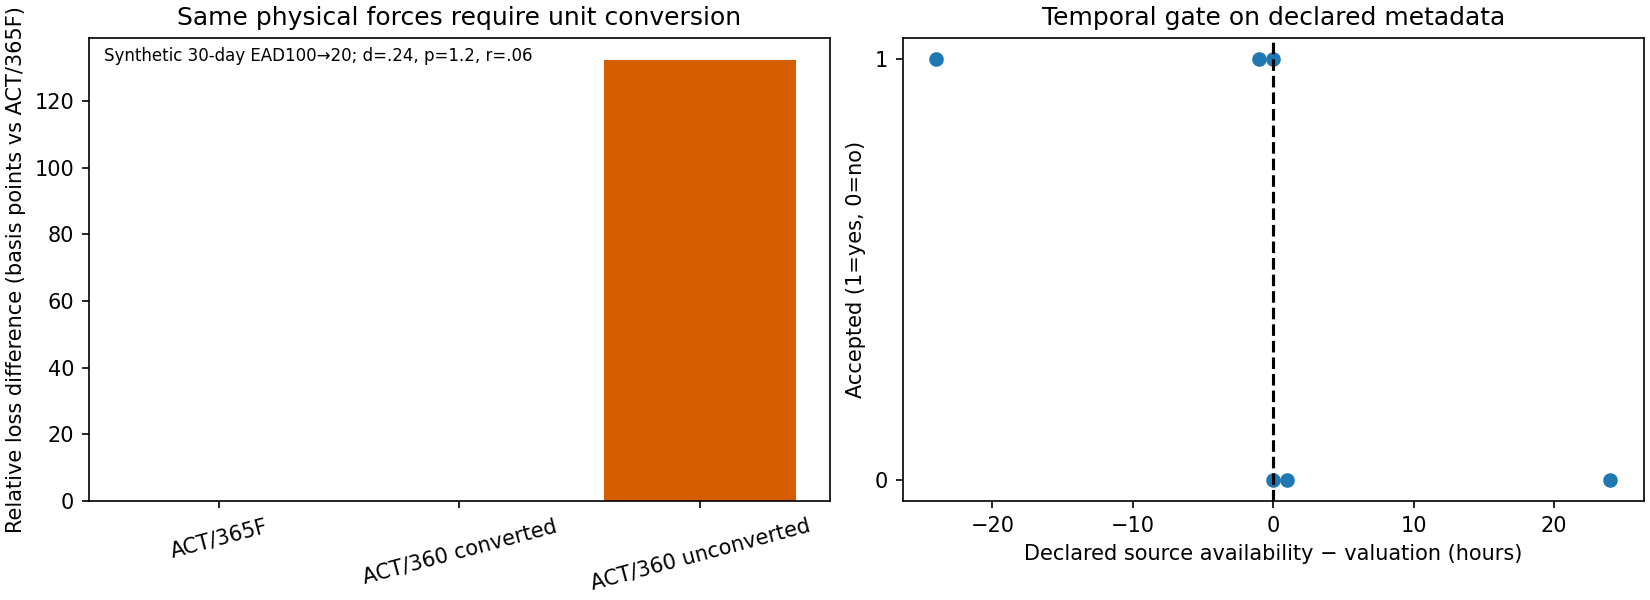

In [3]:
metrics=json.loads((root/'results/dated_metrics.json').read_text())
print(json.dumps(metrics,indent=2))
assert metrics['passed'] and metrics['direct_numeric_error']==0.
for row in csv.DictReader((root/'results/dated_availability.csv').open()):print(row)
display(Image(filename=str(root/'results/dated.png')))

## Negativos, límites y lectura
Con disponibilidad futura se rechaza antes de valorar; timestamps equivalentes con offsets distintos son el mismo instante. La igualdad numérica con el motor anterior descarta una pretendida mejora de cálculo: el aporte es contrato auditable, no performance predictiva. Si timestamps declarados son falsos, este guard no lo descubre.

La ampliación permite preparar consumo de calendarios reales sin afirmar que existen datos reales autorizados. No implementa ACT/ACT, businessday, zonas del contrato independientes, tasa efectiva convertida a fuerza, defaultatómico o regulación. No llamar tasaefectiva a fuerza continua. Válido paraDGP condicionado existente. Continuar cuando haya fixture real autorizado y política de procedencia verificable; ajustar ante fuentes incompletas; no operar sin validación.

Notebook ejecutado fresh-process secuencialIPython con outputs reales; nbformat validado; no kernel aislado ni inspecciónfrontendJupyter. Matriz de5fuentes primarias verificadas,14p y rúbricas en informe1102.

In [4]:
print('Source stamps declared (synthetic):')
for source in sources:print(source)
print((root/'results/tests.txt').read_text())

Source stamps declared (synthetic):
SourceStamp(role='ead', identifier='synthetic-balance-v1', uri='synthetic://balance/v1', available_at=datetime.datetime(2024, 2, 28, 11, 0, tzinfo=datetime.timezone.utc))
SourceStamp(role='hazards', identifier='synthetic-hazards-v1', uri='synthetic://hazards/v1', available_at=datetime.datetime(2024, 2, 27, 12, 0, tzinfo=datetime.timezone.utc))
SourceStamp(role='discount', identifier='synthetic-discount-v1', uri='synthetic://discount/v1', available_at=datetime.datetime(2024, 2, 28, 10, 0, tzinfo=datetime.timezone.utc))
test_constant_reduces_to_original (test_affine.AffineTests.test_constant_reduces_to_original) ... ok
test_decimal_oracle_small_large (test_affine.AffineTests.test_decimal_oracle_small_large) ... ok
test_invalid (test_affine.AffineTests.test_invalid) ... ok
test_negative_direction_and_zero (test_affine.AffineTests.test_negative_direction_and_zero) ... ok
test_partition_invariance_irregular (test_affine.AffineTests.test_partition_invarian